## SMILES

In [1]:
from rdkit.Chem import AllChem
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit import DataStructs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import MLUtils 

from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

import pickle


In [2]:
SEED = 42

In [3]:
de_train_path = "/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/data/de_train.parquet"
de_train = pd.read_parquet(de_train_path)
de_train.head()

,cell_type,sm_name,sm_lincs_id,SMILES,control,A1BG,A1BG-AS1,A2M,A2M-AS1,A2MP1,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1
0,NK cells,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.104720,-0.077524,-1.625596,-0.144545,0.143555,...,-0.227781,-0.010752,-0.023881,0.674536,-0.453068,0.005164,-0.094959,0.034127,0.221377,0.368755
1,T cells CD4+,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.915953,-0.884380,0.371834,-0.081677,-0.498266,...,-0.494985,-0.303419,0.304955,-0.333905,-0.315516,-0.369626,-0.095079,0.704780,1.096702,-0.869887
2,T cells CD8+,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,-0.387721,-0.305378,0.567777,0.303895,-0.022653,...,-0.119422,-0.033608,-0.153123,0.183597,-0.555678,-1.494789,-0.213550,0.415768,0.078439,-0.259365
3,T regulatory cells,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.232893,0.129029,0.336897,0.486946,0.767661,...,0.451679,0.704643,0.015468,-0.103868,0.865027,0.189114,0.224700,-0.048233,0.216139,-0.085024
4,NK cells,Mometasone Furoate,LSM-3349,C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C...,False,4.290652,-0.063864,-0.017443,-0.541154,0.570982,...,0.758474,0.510762,0.607401,-0.123059,0.214366,0.487838,-0.819775,0.112365,-0.122193,0.676629


**Playing Around with SMILES**

In [30]:
de_train['SMILES'].value_counts()

SMILES
Nc1nc(Nc2ccc3c(c2)CC[C@@H](N2CCCC2)CC3)nn1-c1cc2c(nn1)-c1ccccc1CCC2        6
CC(C)C[C@H](NC(=O)CNC(=O)c1cc(Cl)ccc1Cl)B(O)O                              6
Cn1c(=O)n(-c2ccc(C(C)(C)C#N)cc2)c2c3cc(-c4cnc5ccccc5c4)ccc3ncc21           6
c1ccc2c(-c3cnn4cc(-c5ccc(N6CCNCC6)cc5)cnc34)ccnc2c1                        6
O=C(CSc1nc2c(c(=O)n1-c1ccccc1)SCC2)Nc1ccc(-c2ccccc2)cn1                    6
                                                                          ..
Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1                 4
CCn1cc(-c2ccnc3[nH]c(-c4cccc(CN(C)C)c4)cc23)c(-c2ccc(NC(=O)N(C)C)cc2)n1    4
NNC(=O)c1ccncc1                                                            4
CN(C)Cc1ccc(S(=O)(=O)n2ccc(/C=C/C(=O)NO)c2)cc1                             3
OCCCNc1cc(-c2ccnc(Nc3cccc(Cl)c3)n2)ccn1                                    3
Name: count, Length: 146, dtype: int64

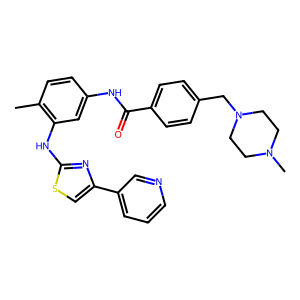

In [ ]:
# Draw chem structure from SMILES
mol= Chem.MolFromSmiles("Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1")
Draw.MolToImage(mol)

In [35]:
# initiate empty bits dictionary 
bits = {}
morganfp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, bitInfo=bits)
morganfp

[15:50:51] DEPRECATION WARNING: please use MorganGenerator


In [ ]:
morganfp.GetNumBits()   # default nBits = 2048

2048

In [41]:
bits

{29: ((7, 1),),
 80: ((6, 0),),
 389: ((2, 2),),
 458: ((6, 1),),
 573: ((7, 2),),
 872: ((6, 2),),
 926: ((8, 0), (9, 0)),
 1019: ((7, 0),),
 1066: ((0, 2), (4, 2)),
 1088: ((1, 1), (2, 1), (3, 1)),
 1199: ((3, 2), (1, 2)),
 1325: ((8, 1), (9, 1)),
 1380: ((5, 0),),
 1456: ((5, 2),),
 1671: ((8, 2),),
 1750: ((4, 1), (0, 1)),
 1754: ((5, 1),),
 1873: ((0, 0), (1, 0), (2, 0), (3, 0), (4, 0))}

In [36]:
arr = np.zeros(2048, dtype=np.int8) # initiate array of length 2048
arr

array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=int8)

In [40]:
DataStructs.ConvertToNumpyArray(morganfp, arr)
arr # converts fingerprint to array

array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=int8)

In [43]:
arr[29]

np.int8(1)

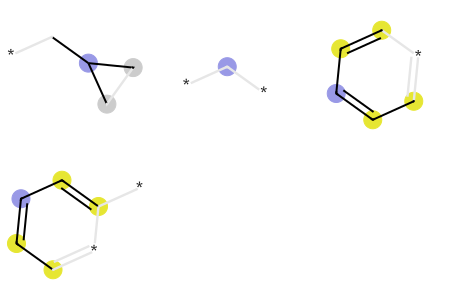

In [ ]:
from IPython.display import display
bits_img = Draw.DrawMorganBits([(mol, 29, bits), (mol, 80, bits), (mol, 389, bits), (mol, 1199, bits)])
display(bits_img)

**Generate Morgan FP for Data**

In [4]:
# takes in SMILES and returns bit vector
def generate_fp(SMILES, radius=2, nBits=1024):
    mol = Chem.MolFromSmiles(SMILES)
    bits = {}
    morganfp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=radius, bitInfo=bits, nBits=nBits)
    arr = np.zeros(nBits, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(morganfp, arr)
    
    return arr

In [5]:
unique_SMILES = de_train["SMILES"].unique()
unique_SMILES

array(['Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1',
       'C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C@@]3(Cl)[C@@H](O)C[C@]2(C)[C@@]1(OC(=O)c1ccco1)C(=O)CCl',
       'CC[C@H](Nc1ncnc2[nH]cnc12)c1nc2cccc(F)c2c(=O)n1-c1ccccc1',
       'COc1cc2c(Nc3ccc(Br)cc3F)ncnc2cc1OCC1CCN(C)CC1',
       'COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc23)c(Cl)cc1Cl',
       'Cc1cc(Nc2ncc(Cl)c(Nc3ccccc3S(=O)(=O)C(C)C)n2)c(OC(C)C)cc1C1CCNCC1',
       'Nc1ccn([C@@H]2CS[C@H](CO)O2)c(=O)n1',
       'C[C@@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl',
       'COc1cc2nccc(Oc3ccc(NC(=O)C4(C(=O)Nc5ccc(F)cc5)CC4)cc3)c2cc1OC',
       'CC(C)C(=O)Nc1ccc([N+](=O)[O-])c(C(F)(F)F)c1',
       'Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(CCO)CC2)n1',
       'Cn1cnc2c(F)c(Nc3ccc(Br)cc3Cl)c(C(=O)NOCCO)cc21',
       'CC(=O)Nc1cccc(-n2c(=O)n(C3CC3)c(=O)c3c(Nc4ccc(I)cc4F)n(C)c(=O)c(C)c32)c1',
       'CC1(C)CCC(CN2CCN(c3ccc(C(=O)NS(=O)(=O)c4ccc(NCC5CCOCC5)c([N+](=O)[O-])c4)c(Oc4cnc5[nH]ccc5c4)c3)CC2)=C(c2ccc(Cl)cc2)C

In [68]:
len(unique_SMILES)

146

In [6]:
# generate morgan fp for each unique SMILES
morgan_fp = {s: {} for s in unique_SMILES}
for s in unique_SMILES:
    bits = generate_fp(s)
    morgan_fp[s] = bits

[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerator
[16:34:23] DEPRECATION WARNING: please use MorganGenerat

In [7]:
morgan_fp

{'Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C@@]3(Cl)[C@@H](O)C[C@]2(C)[C@@]1(OC(=O)c1ccco1)C(=O)CCl': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'CC[C@H](Nc1ncnc2[nH]cnc12)c1nc2cccc(F)c2c(=O)n1-c1ccccc1': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'COc1cc2c(Nc3ccc(Br)cc3F)ncnc2cc1OCC1CCN(C)CC1': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc23)c(Cl)cc1Cl': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'Cc1cc(Nc2ncc(Cl)c(Nc3ccccc3S(=O)(=O)C(C)C)n2)c(OC(C)C)cc1C1CCNCC1': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'Nc1ccn([C@@H]2CS[C@H](CO)O2)c(=O)n1': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'C[C@@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,), dtype=int8),
 'COc1cc2nccc(Oc3ccc(NC(=O)C4(C(=

In [ ]:
len(morgan_fp)  # should be equal len(unique_SMILES)

146

In [16]:
smiles_to_name = de_train.drop_duplicates('SMILES').set_index('SMILES')['sm_name']
smiles_to_name

SMILES
Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1                                                                         Clotrimazole
C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C@@]3(Cl)[C@@H](O)C[C@]2(C)[C@@]1(OC(=O)c1ccco1)C(=O)CCl    Mometasone Furoate
CC[C@H](Nc1ncnc2[nH]cnc12)c1nc2cccc(F)c2c(=O)n1-c1ccccc1                                                         Idelalisib
COc1cc2c(Nc3ccc(Br)cc3F)ncnc2cc1OCC1CCN(C)CC1                                                                    Vandetanib
COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc23)c(Cl)cc1Cl                                                       Bosutinib
                                                                                                                ...        
COc1cc2c(cc1OC(C)C)[C@H](c1ccc(Cl)cc1)N(c1ccc(N(C)C[C@H]3CC[C@H](N4CCN(C)C(=O)C4)CC3)cc1)C(=O)C2                    CGM-097
Cc1cc(C(C)Nc2ccccc2)c2nc(N3CCOCC3)cc(=O)n2c1                                                                        TGX 221
N

In [23]:
fp_df = pd.DataFrame(
    np.stack(list(morgan_fp.values())),
    index=pd.Index(list(morgan_fp.keys())).map(smiles_to_name).rename('sm_name'),
    columns=[f'fp_{i}' for i in range(1024)]
).sort_index()
fp_df

,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,fp_9,...,fp_1014,fp_1015,fp_1016,fp_1017,fp_1018,fp_1019,fp_1020,fp_1021,fp_1022,fp_1023
sm_name,,,,,,,,,,,,,,,,,,,,,
5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine,0,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
ABT-199 (GDC-0199),0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
ABT737,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AMD-070 (hydrochloride),0,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
AT 7867,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vandetanib,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
Vanoxerine,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Vardenafil,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Save Morgan FP
fp_df.to_csv("processed_data/morgan_fingerprints.csv")

### TRAIN

In [84]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

In [5]:
# load one hot cell encodings
ohe_cell = pd.read_csv("/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/processed_data/onehot_cell_type.csv", index_col="cell_type")
ohe_cell

,cell_type_B cells,cell_type_Myeloid cells,cell_type_NK cells,cell_type_T cells CD4+,cell_type_T cells CD8+,cell_type_T regulatory cells
cell_type,,,,,,
B cells,1,0,0,0,0,0
Myeloid cells,0,1,0,0,0,0
NK cells,0,0,1,0,0,0
T cells CD4+,0,0,0,1,0,0
T cells CD8+,0,0,0,0,1,0
T regulatory cells,0,0,0,0,0,1


In [6]:
# convert cell encodings to dict
ohe_cell_map = dict(zip(ohe_cell.index, ohe_cell.to_numpy()))
ohe_cell_map

{'B cells': array([1, 0, 0, 0, 0, 0]),
 'Myeloid cells': array([0, 1, 0, 0, 0, 0]),
 'NK cells': array([0, 0, 1, 0, 0, 0]),
 'T cells CD4+': array([0, 0, 0, 1, 0, 0]),
 'T cells CD8+': array([0, 0, 0, 0, 1, 0]),
 'T regulatory cells': array([0, 0, 0, 0, 0, 1])}

In [7]:
morgan_fp = pd.read_csv("/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/processed_data/morgan_fingerprints.csv", index_col='sm_name')
morgan_fp

,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,fp_9,...,fp_1014,fp_1015,fp_1016,fp_1017,fp_1018,fp_1019,fp_1020,fp_1021,fp_1022,fp_1023
sm_name,,,,,,,,,,,,,,,,,,,,,
5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine,0,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
ABT-199 (GDC-0199),0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
ABT737,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AMD-070 (hydrochloride),0,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
AT 7867,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vandetanib,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
Vanoxerine,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Vardenafil,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
morgan_fp_map = dict(zip(morgan_fp.index, morgan_fp.to_numpy()))
morgan_fp_map

{'5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,)),
 'ABT-199 (GDC-0199)': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'ABT737': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,)),
 'AMD-070 (hydrochloride)': array([0, 0, 1, ..., 0, 0, 0], shape=(1024,)),
 'AT 7867': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'AT13387': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,)),
 'AVL-292': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'AZ628': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'AZD-8330': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'AZD3514': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'AZD4547': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'Alogliptin': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'Alvocidib': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'Amiodarone': array([0, 0, 0, ..., 0, 0, 0], shape=(1024,)),
 'Atorvastatin': array([0, 1, 0, ..., 0, 0, 0], shape=(1024,)),
 'Azacitidine': 

**PICKLE SPLITZZ**

In [9]:
path = "/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/processed_data/train_test_splits.pkl"
with open(path, "rb") as f:
    folds = pickle.load(f)

In [10]:
X_tr, y_tr = MLUtils.featurize_cell_sm(de_train, ohe_cell_map, morgan_fp_map)
rf_model = RandomForestRegressor(min_samples_leaf=2, random_state=SEED, oob_score=True)
pca_y = PCA(n_components=50)
MLUtils.train(X_tr, y_tr, rf_model, folds, pca_y)

{'folds': [1.157466498025422,
  1.1045010375500817,
  1.5283404165247756,
  1.2661399140642633,
  1.382426327235497,
  1.1044060191666296,
  1.042024306766479,
  1.093668898692862,
  1.2109666153141134,
  1.4853298045371095],
 'mean': 1.2375269837877232}

In [11]:
X_tr, y_tr = MLUtils.featurize_cell_sm(de_train, ohe_cell_map, morgan_fp_map)
ridge_model = RidgeCV(alphas=[1e-3, 1e-2, 1e-1, 1, 10, 100])
pca_y = PCA(n_components=50)
MLUtils.train(X_tr, y_tr, ridge_model, folds, pca_y)

{'folds': [1.1866625181496806,
  1.1048287397320344,
  1.5251872366519201,
  1.2240988647962687,
  1.5019948686821178,
  1.1495810677636507,
  0.9820063395930974,
  1.046973235257644,
  1.1856823965991168,
  1.5211245901873558],
 'mean': 1.2428139857412885}

### OTHER ALGORITHMS

In [21]:
# TODO: Common models used on FP

### LOGO

In [12]:
X_tr, y_tr = MLUtils.featurize_cell_sm(de_train, ohe_cell_map, morgan_fp_map)
rf_model = RandomForestRegressor(min_samples_leaf=2, random_state=SEED, oob_score=True)
pca_y = PCA(n_components=50)
groups = de_train['cell_type'].to_numpy()
MLUtils.train_logo(X_tr, y_tr, groups, rf_model, pca_y)

hold out group B cells: MRRMSE = 2.1881549483748737
hold out group Myeloid cells: MRRMSE = 2.8650460496644787
hold out group NK cells: MRRMSE = 1.217402629015281
hold out group T cells CD4+: MRRMSE = 1.1973790400282007
hold out group T cells CD8+: MRRMSE = 1.0399302339330447
hold out group T regulatory cells: MRRMSE = 1.2719940447983633


{'folds': [2.1881549483748737,
  2.8650460496644787,
  1.217402629015281,
  1.1973790400282007,
  1.0399302339330447,
  1.2719940447983633],
 'mean': 1.6299844909690406}

### Examine Morgan FP

In [64]:
pca = PCA(n_components=146)
pca.fit_transform(morgan_fp.values)

array([[-7.01760068e-01,  7.53369222e-01, -5.65863942e-01, ...,
        -1.96999444e-02,  1.81515839e-02,  2.12238234e-15],
       [ 2.66583479e+00,  4.56855126e+00,  6.76135954e-01, ...,
         5.21161390e-02,  3.24730493e-02,  2.12238234e-15],
       [ 1.50000317e+00,  3.63000351e+00, -3.82543233e-01, ...,
        -5.65973019e-02, -1.37333059e-02,  2.12238234e-15],
       ...,
       [ 2.57961951e-01,  9.96169649e-01,  4.25160622e-01, ...,
        -5.93915228e-02,  1.66458279e-02,  2.12238234e-15],
       [-9.46202702e-01, -1.62148928e+00, -2.13823107e-01, ...,
         1.08598569e-01, -8.51509818e-02,  2.12238234e-15],
       [-5.40346598e-01, -2.46556151e-01,  1.39061012e+00, ...,
         2.72662829e-02, -1.84294344e-02,  2.12238234e-15]],
      shape=(146, 146))

In [65]:
var = np.cumsum(pca.explained_variance_ratio_)

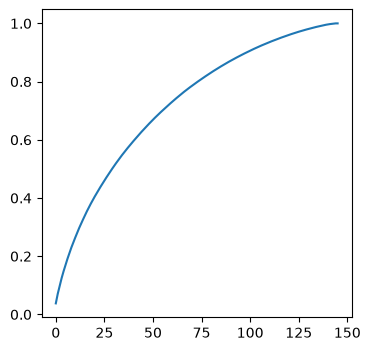

In [66]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))
ax.plot(var)